# Proyecto Final - Text Mining & Image Recognition
## Problema 1 - Word Cloud

**Autor:** Fabio Humberto Suruy Juarez
**Carne:** 25001013
**Postgrado en Analisis y Prediccion de Datos**

Dataset: tweets en formato Sentiment140 (`target, id, date, flag, user, text`).

**Objetivo:**
1. Determinar los 3 usuarios mas populares del dataset (usando expresiones regulares para
   detectar menciones `@usuario` dentro del texto de los tweets).
2. Armar un corpus por cada usuario seleccionado con `Content` (tweet) y `Metadata`
   (ID, Timestamp, Length).
3. Analizar el contexto real alrededor de cada mencion (ventana de palabras, stopwords,
   stemming, lematizacion) para responder *¿por que citan a ese usuario?*
4. Mostrar un wordcloud con el top 10 de palabras de contexto para cada usuario.


In [1]:
import re
import time
import pandas as pd
import numpy as np
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import TweetTokenizer

from wordcloud import WordCloud
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option('display.max_colwidth', 120)


## 1. Carga del dataset

El CSV no trae encabezados; las columnas siguen el formato estandar del dataset de tweets (Sentiment140): `target, id, date, flag, user, text`.

In [2]:
COLUMNS = ['target', 'id', 'date', 'flag', 'user', 'text']
DATA_PATH = 'tw_source.csv'

df = pd.read_csv(DATA_PATH, encoding='latin-1', names=COLUMNS, header=None)
print('Numero de tweets en el dataset:', len(df))
df.head()


Numero de tweets en el dataset: 1600000


,target,id,date,flag,user,text
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr of Third Day to do it. ;D"
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by texting it... and might cry as a result School today also. Blah!
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Managed to save 50% The rest go out of bounds
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all. i'm mad. why am i here? because I can't see you all over there."


> **Nota:** el enunciado menciona ~800,000 tweets; el archivo entregado (`tw_source.csv`,
> dataset Sentiment140) contiene en realidad 1,600,000 registros. Se documenta la diferencia
> por transparencia; el analisis se realiza sobre el dataset completo tal como fue provisto.


## 2. Determinar los 3 usuarios mas populares (regex)

"Usuario popular" puede interpretarse de 2 formas. Se calculan **ambas** con expresiones
regulares para dejar la eleccion documentada:

- **(A) Usuario mas citado/mencionado**: cuantas veces aparece `@usuario` en el texto de
  *otros* tweets. Esta es la interpretacion elegida como principal, porque la pregunta de
  negocio del enunciado es *¿por que citan a ese usuario?*, lo cual solo tiene sentido para
  menciones.
- **(B) Autor mas activo**: que usuario (columna `user`) escribio mas tweets. Se incluye como
  referencia para dejar clara la diferencia frente a (A).


In [3]:
MENTION_RE = re.compile(r'@([A-Za-z0-9_]{1,15})')

def extract_mentions(text):
    if not isinstance(text, str):
        return []
    return [m.lower() for m in MENTION_RE.findall(text)]

df['mentions'] = df['text'].apply(extract_mentions)

mention_counter = Counter()
for mentions in df['mentions']:
    mention_counter.update(mentions)

top3_mentioned = [u for u, _ in mention_counter.most_common(3)]

print('(A) Top 3 usuarios MAS MENCIONADOS (@usuario en el texto):')
for u, c in mention_counter.most_common(3):
    print(f'   @{u}: {c} menciones')

# (B) Autor mas activo, tambien validado con regex (nombre de usuario valido de Twitter)
VALID_USERNAME_RE = re.compile(r'^[A-Za-z0-9_]{1,15}$')
valid_authors = df.loc[df['user'].str.match(VALID_USERNAME_RE, na=False), 'user'].str.lower()
author_counter = Counter(valid_authors)
top3_authors = author_counter.most_common(3)

print('\n(B) Top 3 usuarios MAS ACTIVOS (autores con mas tweets publicados):')
for u, c in top3_authors:
    print(f'   @{u}: {c} tweets')

top3_users = top3_mentioned
print('\n>> Se usara la interpretacion (A) — usuarios mas mencionados — para el resto del analisis.')


(A) Top 3 usuarios MAS MENCIONADOS (@usuario en el texto):
   @mileycyrus: 4580 menciones
   @tommcfly: 3904 menciones
   @ddlovato: 3474 menciones



(B) Top 3 usuarios MAS ACTIVOS (autores con mas tweets publicados):
   @lost_dog: 549 tweets
   @webwoke: 345 tweets
   @tweetpet: 310 tweets

>> Se usara la interpretacion (A) — usuarios mas mencionados — para el resto del analisis.


## 3. Construccion del corpus por usuario

Para cada uno de los 3 usuarios (interpretacion A) se arma un corpus con `Content` (tweet) y `Metadata` (`ID`, `Timestamp`, `Length`).

In [4]:
def build_corpus(df, username):
    mask = df['mentions'].apply(lambda ms: username in ms)
    subset = df.loc[mask, ['id', 'date', 'text']].copy()
    subset['length'] = subset['text'].str.len()
    corpus = subset.rename(columns={'id': 'ID', 'date': 'Timestamp', 'text': 'Content', 'length': 'Length'})
    return corpus[['Content', 'ID', 'Timestamp', 'Length']].reset_index(drop=True)

corpora = {u: build_corpus(df, u) for u in top3_users}

for u, corpus in corpora.items():
    print(f'--- Corpus de @{u}: {len(corpus)} tweets | Length promedio: {corpus["Length"].mean():.1f} caracteres ---')
    display(corpus.head(3))


--- Corpus de @mileycyrus: 4562 tweets | Length promedio: 85.2 caracteres ---


,Content,ID,Timestamp,Length
0,@mileycyrus hahaha dont be like that one time in NY when you got 30 mins of sleep then got sick love you!!,1468063101,Mon Apr 06 23:30:57 PDT 2009,107
1,"@mileycyrus i have the same problem, but it's 4:43 here... let's see if counting works..1234...56 57 58... 132 133 1...",1468286517,Tue Apr 07 00:45:20 PDT 2009,137
2,@mileycyrus I guess counting sheep didn't work Hope you get some sleep!,1468297110,Tue Apr 07 00:49:07 PDT 2009,72


--- Corpus de @tommcfly: 3898 tweets | Length promedio: 86.6 caracteres ---


,Content,ID,Timestamp,Length
0,@tommcfly hey saw u guys play @ pushover..didn't get 2 meet u tho cuz of th HUGE line i was very upset ='( lol..a m...,1468210813,Tue Apr 07 00:19:09 PDT 2009,138
1,@tommcfly Good morning Tom! Why can't I send you a message? This is too short for the question I have Well to bad f...,1468233211,Tue Apr 07 00:26:52 PDT 2009,131
2,@tommcfly did you know that johnsons baby use animals like cute bunnies to test their products?,1468391638,Tue Apr 07 01:23:07 PDT 2009,96


--- Corpus de @ddlovato: 3460 tweets | Length promedio: 87.6 caracteres ---


,Content,ID,Timestamp,Length
0,@ddlovato @David_Henrie ummmmm i cant find it.,1467929230,Mon Apr 06 22:51:34 PDT 2009,47
1,@ddlovato Do you hate us?? Please don't,1467953367,Mon Apr 06 22:58:30 PDT 2009,40
2,@ddlovato Wish that i could see it.. Thats the downside of living in Sweden.. Good Luck anyway,1469661950,Tue Apr 07 07:02:58 PDT 2009,96


In [5]:
import os
os.makedirs('outputs', exist_ok=True)
for u, corpus in corpora.items():
    corpus.to_csv(f'outputs/corpus_{u}.csv', index=False)
print('Corpus guardados en outputs/')


Corpus guardados en outputs/


## 4. Extraccion de contexto alrededor de la mencion

A diferencia de usar el tweet completo, aqui se toma una **ventana real de palabras** alrededor
de cada aparicion de `@usuario` dentro del tweet (tokenizado con `TweetTokenizer`, que preserva
menciones, hashtags y emoticonos tal como aparecen en Twitter). Luego se limpia el contexto
(URLs, mencion, puntuacion, stopwords de NLTK + ruido propio de Twitter como `quot`/`amp`/`rt`),
y se muestra, para el mismo texto, el resultado de aplicar **stemming** y **lematizacion** por
separado, ya que aplicarlos encadenados (stem -> lemma) puede destruir palabras validas
(por ejemplo `please` -> stem `pleas` -> lemma `plea`, que ya no es la palabra original).


In [6]:
stop_words = set(stopwords.words('english'))
TWITTER_NOISE = {'quot', 'amp', 'rt', 'lt', 'gt', 'im', 'u', 'ur', 'wa', 'ha', 'r', 'n'}
stop_words |= TWITTER_NOISE

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
tknzr = TweetTokenizer(preserve_case=False, reduce_len=True, strip_handles=False)

URL_RE = re.compile(r'https?://\S+|www\.\S+')
NON_ALPHA_RE = re.compile(r'[^a-zA-Z\s]')
WINDOW = 5  # palabras de contexto a cada lado de la mencion

def extract_context_window(text, username, window=WINDOW):
    """Devuelve los tokens crudos (sin limpiar) dentro de la ventana alrededor de cada
    aparicion de @username en el tweet tokenizado."""
    if not isinstance(text, str):
        return []
    clean = URL_RE.sub(' ', text)
    tokens = tknzr.tokenize(clean)
    mention_token = '@' + username.lower()
    positions = [i for i, t in enumerate(tokens) if t == mention_token]
    context = []
    for pos in positions:
        start = max(0, pos - window)
        end = min(len(tokens), pos + window + 1)
        context.extend(tokens[start:pos] + tokens[pos + 1:end])
    return context

def clean_tokens(tokens):
    cleaned = []
    for t in tokens:
        t = t.replace("'", '')          # dont, cant en vez de don t / can t
        t = NON_ALPHA_RE.sub('', t)
        if len(t) > 2 and t not in stop_words:
            cleaned.append(t)
    return cleaned

def get_context_tokens_lemmatized(text, username, window=WINDOW):
    raw = extract_context_window(text, username, window)
    cleaned = clean_tokens(raw)
    return [lemmatizer.lemmatize(t) for t in cleaned]

def get_context_tokens_stemmed(text, username, window=WINDOW):
    raw = extract_context_window(text, username, window)
    cleaned = clean_tokens(raw)
    return [stemmer.stem(t) for t in cleaned]

def context_word_freq(corpus, username, fn):
    counter = Counter()
    for text in corpus['Content']:
        counter.update(fn(text, username))
    return counter

# --- Ejemplo comparativo: stemming vs lematizacion sobre el mismo tweet ---
ejemplo_texto = corpora[top3_users[0]]['Content'].iloc[0]
ejemplo_raw = extract_context_window(ejemplo_texto, top3_users[0])
ejemplo_clean = clean_tokens(ejemplo_raw)
print('Tweet de ejemplo:', ejemplo_texto)
print('Contexto (ventana de', WINDOW, 'palabras, limpio):', ejemplo_clean)
print('  -> Stemming    :', [stemmer.stem(t) for t in ejemplo_clean])
print('  -> Lematizacion:', [lemmatizer.lemmatize(t) for t in ejemplo_clean])


Tweet de ejemplo: @mileycyrus hahaha dont be like that one time in NY when you got 30 mins of sleep then got sick  love you!!
Contexto (ventana de 5 palabras, limpio): ['hahaha', 'dont', 'like']
  -> Stemming    : ['hahaha', 'dont', 'like']


  -> Lematizacion: ['hahaha', 'dont', 'like']


Se observa que la **lematizacion** produce palabras reales del diccionario (mejores para
mostrar en un wordcloud legible), mientras que el **stemming** es mas agresivo y puede truncar
palabras. Por eso el wordcloud final del top 10 se construye con las palabras **lematizadas**,
dejando el stemming documentado como paso realizado y disponible para comparacion.


In [7]:
context_counters_lemma = {u: context_word_freq(corpora[u], u, get_context_tokens_lemmatized) for u in top3_users}
context_counters_stem = {u: context_word_freq(corpora[u], u, get_context_tokens_stemmed) for u in top3_users}

for u in top3_users:
    print(f'--- Top 10 palabras de contexto (lematizado) para @{u} ---')
    for word, freq in context_counters_lemma[u].most_common(10):
        print(f'   {word}: {freq}')
    print()


--- Top 10 palabras de contexto (lematizado) para @mileycyrus ---
   miley: 571
   love: 303
   hey: 174
   good: 165
   dont: 132
   come: 122
   vote: 121
   hope: 120
   luck: 101
   youre: 101

--- Top 10 palabras de contexto (lematizado) para @tommcfly ---
   tom: 555
   say: 163
   hey: 154
   good: 127
   please: 126
   dont: 123
   love: 112
   dannymcfly: 93
   reply: 89
   haha: 87

--- Top 10 palabras de contexto (lematizado) para @ddlovato ---
   demi: 413
   love: 199
   wish: 146
   hey: 119
   cant: 111
   hope: 92
   please: 90
   come: 89
   youre: 88
   selenagomez: 86



## 5. ¿Por que citan a ese usuario?

A partir del top 10 de palabras de contexto real (ventana alrededor de la mencion) se infiere
el motivo de la cita para cada usuario, apoyandose en categorias tematicas simples (cariño,
peticion/deseo, voto/campaña, conversacion informal, queja) y verificando si el propio nombre
del usuario aparece como palabra de contexto (evidencia de que se le nombra/identifica
directamente).


In [8]:
KEYWORD_BUCKETS = {
    'carino/fandom': {'love', 'miss', 'beautiful', 'amazing', 'cute', 'best', 'proud'},
    'peticion/deseo': {'please', 'wish', 'hope', 'want', 'need', 'wait', 'plz'},
    'voto/campana': {'vote', 'voting', 'poll', 'award'},
    'conversacion informal': {'haha', 'lol', 'yeah', 'say', 'guy', 'lmao', 'omg'},
    'queja/soporte': {'sorry', 'bad', 'hate', 'worst', 'problem', 'fix', 'sad'},
}

def analizar_usuario(u):
    top10 = context_counters_lemma[u].most_common(10)
    top10_words = {w for w, _ in top10}
    matches = {cat: sorted(top10_words & kws) for cat, kws in KEYWORD_BUCKETS.items() if top10_words & kws}
    name_hits = [w for w in top10_words if w in u or u.startswith(w)]
    return top10, matches, name_hits

for u in top3_users:
    top10, matches, name_hits = analizar_usuario(u)
    texto = [f"**@{u}** (top 10: {', '.join(w for w, _ in top10)})"]
    if name_hits:
        texto.append(f"- El propio nombre aparece en el contexto ({', '.join(name_hits)}), confirmando que se le identifica directamente.")
    for cat, words in matches.items():
        texto.append(f"- Categoria detectada **{cat}**: {', '.join(words)}")
    if not matches:
        texto.append('- No se detecto una categoria tematica dominante en el top 10; revisar manualmente.')
    display(Markdown('\n'.join(texto)))


**@mileycyrus** (top 10: miley, love, hey, good, dont, come, vote, hope, luck, youre)
- El propio nombre aparece en el contexto (miley), confirmando que se le identifica directamente.
- Categoria detectada **carino/fandom**: love
- Categoria detectada **peticion/deseo**: hope
- Categoria detectada **voto/campana**: vote

**@tommcfly** (top 10: tom, say, hey, good, please, dont, love, dannymcfly, reply, haha)
- El propio nombre aparece en el contexto (tom), confirmando que se le identifica directamente.
- Categoria detectada **carino/fandom**: love
- Categoria detectada **peticion/deseo**: please
- Categoria detectada **conversacion informal**: haha, say

**@ddlovato** (top 10: demi, love, wish, hey, cant, hope, please, come, youre, selenagomez)
- Categoria detectada **carino/fandom**: love
- Categoria detectada **peticion/deseo**: hope, please, wish

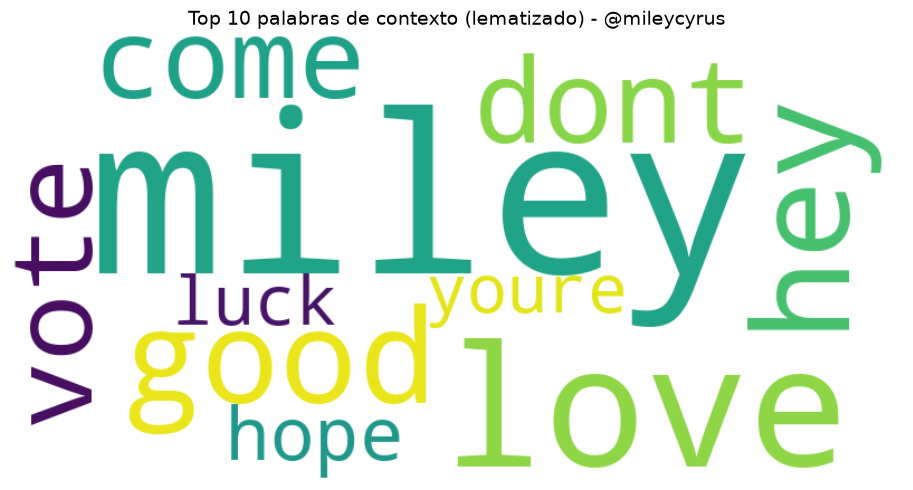

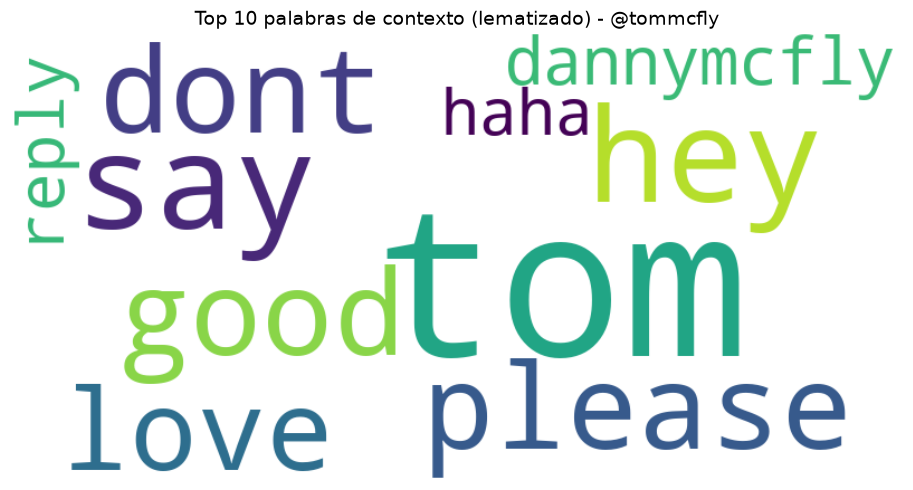

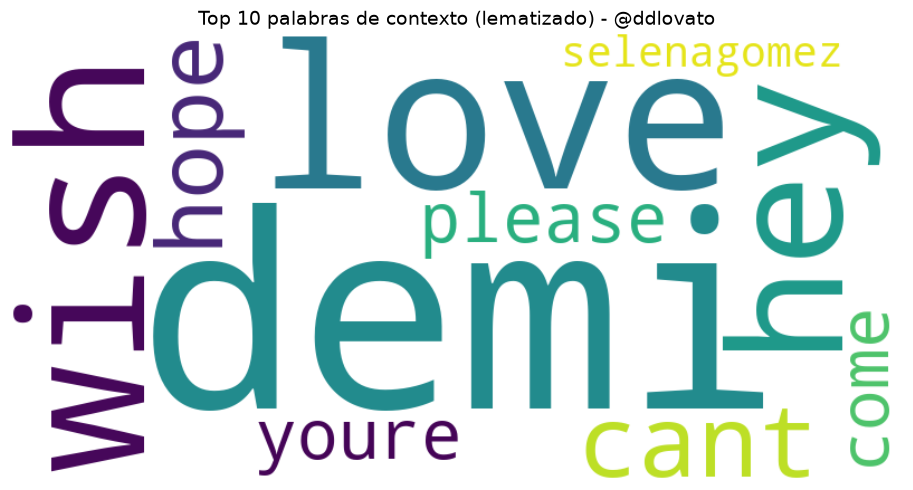

In [9]:
def plot_wordcloud(counter, username):
    top10 = dict(counter.most_common(10))
    wc = WordCloud(width=800, height=400, background_color='white', colormap='viridis')
    wc.generate_from_frequencies(top10)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Top 10 palabras de contexto (lematizado) - @{username}', fontsize=14)
    plt.tight_layout()
    plt.savefig(f'outputs/wordcloud_{username}.png', dpi=150)
    plt.show()

for u in top3_users:
    plot_wordcloud(context_counters_lemma[u], u)


In [10]:
resumen = []
for u in top3_users:
    top10 = context_counters_lemma[u].most_common(10)
    resumen.append({
        'usuario': '@' + u,
        'menciones_totales': mention_counter[u],
        'tweets_en_corpus': len(corpora[u]),
        'top_10_contexto_lematizado': ', '.join(w for w, _ in top10),
    })
resumen_df = pd.DataFrame(resumen)
resumen_df.to_csv('outputs/resumen_top3_usuarios.csv', index=False)
resumen_df


,usuario,menciones_totales,tweets_en_corpus,top_10_contexto_lematizado
0,@mileycyrus,4580,4562,"miley, love, hey, good, dont, come, vote, hope, luck, youre"
1,@tommcfly,3904,3898,"tom, say, hey, good, please, dont, love, dannymcfly, reply, haha"
2,@ddlovato,3474,3460,"demi, love, wish, hey, cant, hope, please, come, youre, selenagomez"


## 6. Comparacion: usuarios mas mencionados vs. autores mas activos

Como referencia adicional (interpretacion B, seccion 2), se listan los 3 autores que mas
tweets publicaron en el dataset, para dejar constancia de que son entidades distintas de los
usuarios mas citados analizados arriba.


In [11]:
pd.DataFrame(top3_authors, columns=['usuario_autor', 'tweets_publicados'])


,usuario_autor,tweets_publicados
0,lost_dog,549
1,webwoke,345
2,tweetpet,310
